# Real Chariklo occultation: sparse chords to a projected silhouette

## 1. Problem

Recover the projected elliptical silhouette of a distant minor planet from five timed stellar-occultation chords and a station that observed no disappearance.

Five positive instrument records at four observing sites provide ten disappearance/reappearance contacts. A negative Hakos record constrains the silhouette further. The recovered object is a five-parameter two-dimensional ellipse, not a textured image or a full3Dbody. Its360boundary points are a redundant display of those five unknowns.


## 2. Data

All keys in `data/raw_data.npz` are batch first.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| limb_points | (1, 10, 2) | float64 | Observing-ray coordinates at measured contacts, km; axes contact,(f,g) |
| velocity | (1, 10, 2) | float64 | Known local ray velocity at each contact, km/s; axes contact,(f,g) |
| timing_sigma | (1, 10) | float64 | Author-example contact uncertainty weights, s |
| times_jd | (1, 10) | float64 | Contact times, Julian day UTC |
| negative_path | (1, 2394, 2) | float64 | Full Hakos non-occultation trajectory sampled every0.5s, km; axes sample,(f,g) |
| contour_angles | (1, 360) | float64 | Fixed output polar angles 0inclusive to2pi exclusive, rad |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Event | 2017-06-22 | UTC date | Real multi-station stellar occultation |
| Contacts | Outeniqua I/E,Onduruquea I/E,Tivoli I/E,Windhoek C14 I/E,Windhoek D16 I/E | ordered records | Immersion then emersion for every instrument |
| Sky axes | f positive east, g positive north | km | Plane perpendicular to star direction; origin is supplied ephemeris/star reference, not the unknown body center |
| Known star direction | 18h55m15.65210s,-31deg31arcmin21.6676arcsec at J2016.0 | ICRS | Author-example Gaia astrometry |
| Star motion | pmRA3.556,pmDec-2.050; parallax0.2121; radial velocity-40.49 | mas/year; mas; km/s | Known calibration used to compute public ray geometry |
| Outeniqua | longitude16:49:17.710E,latitude21:17:58.170S,height1416 | degree notation; m | Positive station |
| Onduruquea | 15:59:33.750E,21:36:26.040S,1220 | degree notation; m | Positive station |
| Tivoli | 18:01:01.240E,23:27:40.190S,1344 | degree notation; m | Positive station |
| Windhoek | 17:06:31.900E,22:41:55.160S,1902 | degree notation; m | Two separate positive instruments at one location |
| Hakos | 16:21:41.320E,23:14:11.040S,1843 | degree notation; m | Negative station |
| Hakos sampled window | 21:10:19.960588 to21:30:16.954860 on event date | UTC | Author cadence file's actual first/last sample after loading; sampled every0.5s, excluding final endpoint |
| Contact uncertainty | supplied timing_sigma; intentionally increased in author teaching example | s | These are author-example fitting weights, not a claim of original published measurement precision |
| Radial uncertainty | norm(velocity)*timing_sigma | km | Source contact-weight convention |
| Timing forward check | local straight ray at each supplied contact coordinate and velocity | km,s | Solve its intersections with the ellipse; nearest time shift compared with timing_sigma |
| Geometry calibration | bundled Chariklo ephemeris and de438_small; Chariklo kernel ID20010199; fixed geocenter; bundled Earth orientation | - | Public ray arrays already include this calibration; no ephemeris package is required |

There are exactly five free geometric parameters. Stellar astrometry, station positions and trajectory calibration are fixed inputs. The author's Hakos example flux column is identically one; it supplies example cadence and a declared negative status, rather than raw measured photometry. No independent body-surface truth is supplied. Elliptical shape, the continuous negative-window assumption, inflated example weights and linearized contact trajectories limit physical interpretation.


The real2017event timings are supplied through the author's example. Its errors are intentionally enlarged teaching weights. The negative example's constant-one flux column supplies declared non-occultation status and cadence, not raw photometry. Both uncertainty and negative-coverage assumptions remain visible.


## 3. Physics

Recover Chariklo's two-dimensional projected ellipse during the real 2017-06-22 event in Namibia. Five positive instrument records from four sites provide ten contacts; Hakos provides a negative record. The public limb points are known sky-plane positions of each observing ray at the measured contact time, derived from independent stellar/ephemeris calibration. Their coordinates are indirect timing constraints, not independent shape measurements.

Let f,g be coordinates in the sky plane, f0,g0 the unknown center in km, a the semi-major axis in km, o the dimensionless oblateness, b=a(1-o), and phi the pole position angle in degrees modulo 180. The pole is the minor-axis direction, measured clockwise from positive north. The polar limb around the center is


$$
r(\theta)=\frac{ab}{\sqrt{a^2\sin^2(\theta+\phi\pi/180)+b^2\cos^2(\theta+\phi\pi/180)}},
\quad (f,g)=(f_0,g_0)+r(\theta)(\cos\theta,\sin\theta).
$$


Here theta is the counterclockwise polar angle from positive f. A positive contact must lie on this boundary within its timing uncertainty, while every sampled ray in the negative record must remain outside. The supplied local ray velocity converts timing uncertainty into distance uncertainty. Limited chord orientations, shared-station observations and uncertainty in the timings make the five geometry parameters correlated and nonunique.


For semi-major radius a, semi-minor b=a(1-o), pole angle phi and sky-plane polar direction theta, r=ab/sqrt((a*sin(theta+phi))^2+(b*cos(theta+phi))^2). Shift by the unknown east/north center. Each timed contact is mapped to this plane using independently known star/station/ephemeris geometry. Its radial error is local ray speed times timing sigma. Search sums the ten squared radial residuals divided by those variances.


## 4. Method

### Original method and actual comparison groups

The original search draws100000uniform trials per batch, clips oblateness as specified, and keeps trials within10of that batch's best chi-square until at least20000are accumulated. The continuous0.5snegative-path filter then rejects every ellipse crossing Hakos. The source's separate exposure-aware filter, using1s exposures and0.1s internal samples, is also reproduced below from known exposure geometry. Both original source runs are separately identified. We additionally perform a complete independent-seed search to expose stochastic and geometric uncertainty.

No archived source ellipse is substituted for a fresh output. The fresh solver computes all contacts and the complete negative filter; original arrays are loaded only for explicitly labeled comparisons.


## 5. Results

The preserved code below contains the active reconstruction and comparison path. Its saved outputs are retained from the earlier execution. This documentation edit does not rerun that path; displayed measurements remain evidence of the stored execution rather than a new numerical run.


In [1]:
from pathlib import Path
import os,sys,time,json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
root=Path.cwd()
if not (root/'src').exists():root=root.parent
os.chdir(root);sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.physics_model import negative_margin
from src.visualization import make_figures
start=time.perf_counter();data=load_data();output,stages=reconstruct(data)
seconds=time.perf_counter()-start
(root/'output').mkdir(exist_ok=True);np.savez(root/'output/reconstruction.npz',**output)
print('Fresh full benchmark seconds:',seconds)
print('Fresh best [f0 km,g0 km,a km,oblateness,PA degree]:',output['parameters'][0])
print('All retained/negative-clear:',len(stages['chi2']),stages['negative_clear'].sum())


Fresh full benchmark seconds: 2.596774400000868
Fresh best [f0 km,g0 km,a km,oblateness,PA degree]: [ 1.07613262e+01 -3.10624700e+00  1.37790156e+02  7.21917792e-02
  1.20043316e+02]
All retained/negative-clear: 20621 19776


In [2]:
start_other=time.perf_counter();seed_output,seed_stages=reconstruct(data,seed=24714)
with np.load(root/'notebooks/reference_outputs/upstream_candidates.npz',allow_pickle=False) as z:upstream={k:z[k] for k in z.files}
with np.load(root/'notebooks/reference_outputs/upstream_exposure_comparison.npz',allow_pickle=False) as z:exposure={k:z[k] for k in z.files}
exposure_clear=np.array([negative_margin(p,exposure['exposure_path'])>0 for p in stages['parameters']])
exposure_parameters=stages['parameters'][exposure_clear]
assert len(exposure_parameters)==len(exposure['parameters'])==19975
np.testing.assert_allclose(exposure_parameters,exposure['parameters'],atol=1e-10)
keys=['center_f','center_g','equatorial_radius','oblateness','position_angle']
i=np.argmin(upstream['chi2']);source_best=np.array([upstream[k][i] for k in keys])
config=json.loads((root/'evaluation/metrics.json').read_text(encoding='utf8'))
comparison={'source_best':source_best,'seed_best':seed_output['parameters'][0],'exposure_parameters':exposure_parameters,'parameter_bounds':np.array([config[k+'_boundary'] for k in ['center_f_error','center_g_error','radius_error','oblateness_error','position_angle_error']])}
print('Actually computed additional-seed/exposure comparison seconds:',time.perf_counter()-start_other)
print('Exposure-aware retained:',exposure_clear.sum())


Actually computed additional-seed/exposure comparison seconds: 6.827359599999909
Exposure-aware retained: 19975


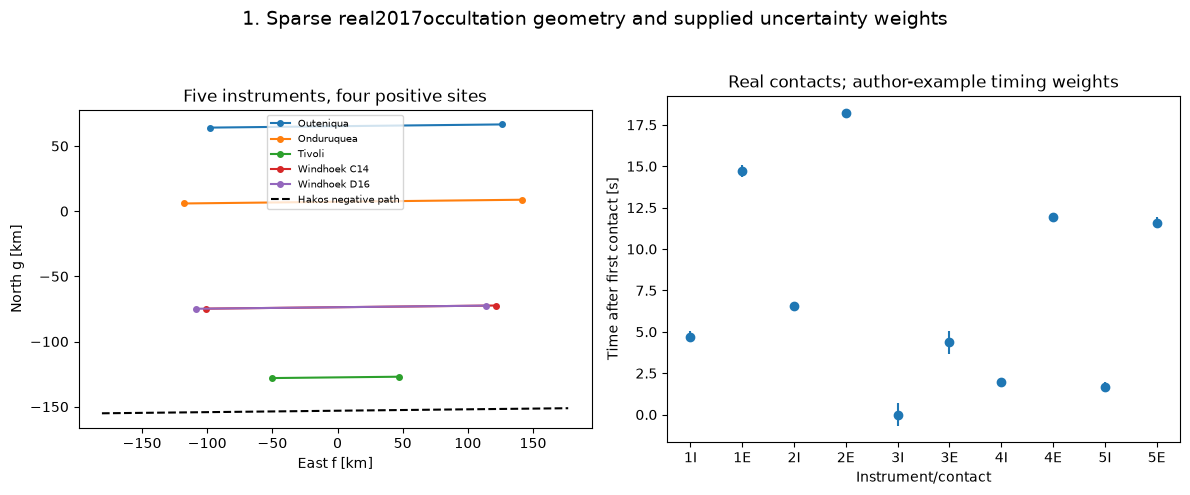

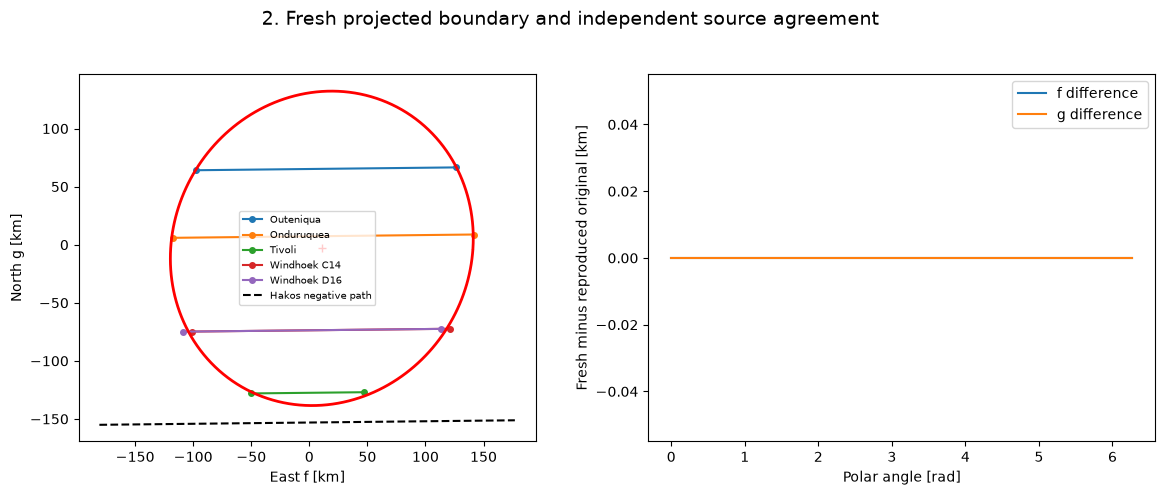

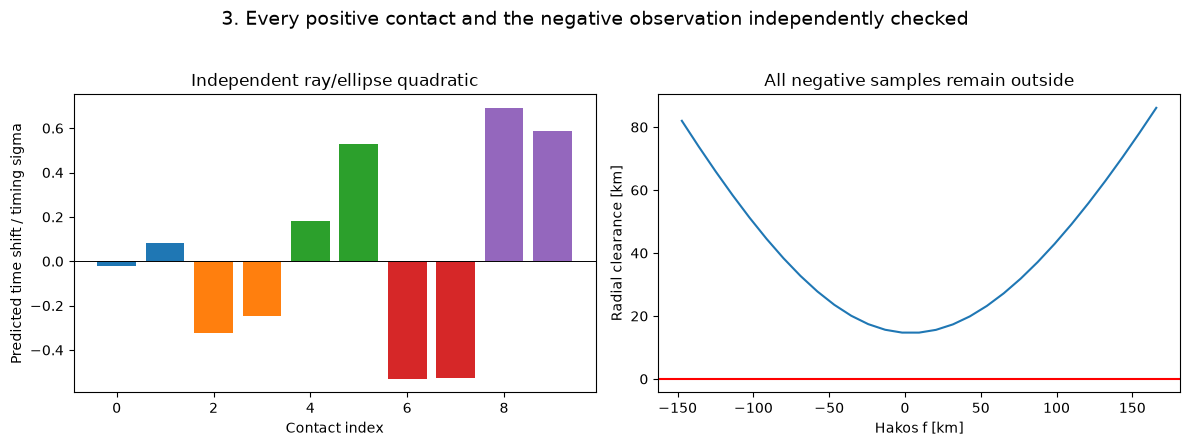

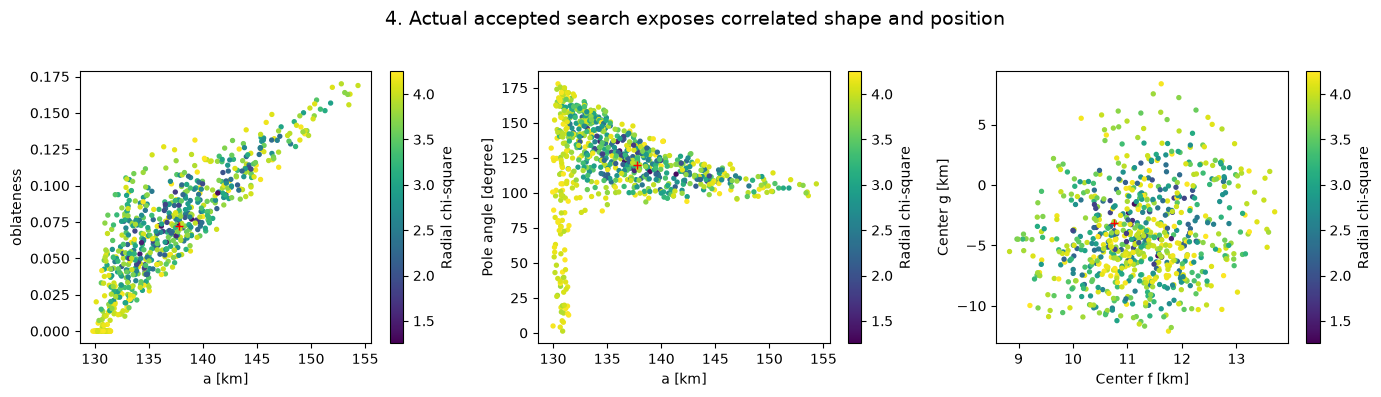

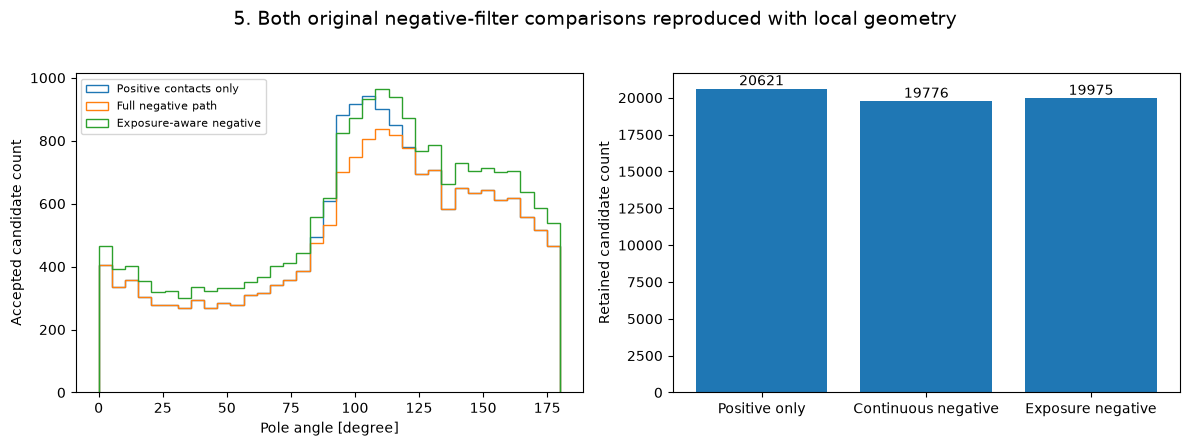

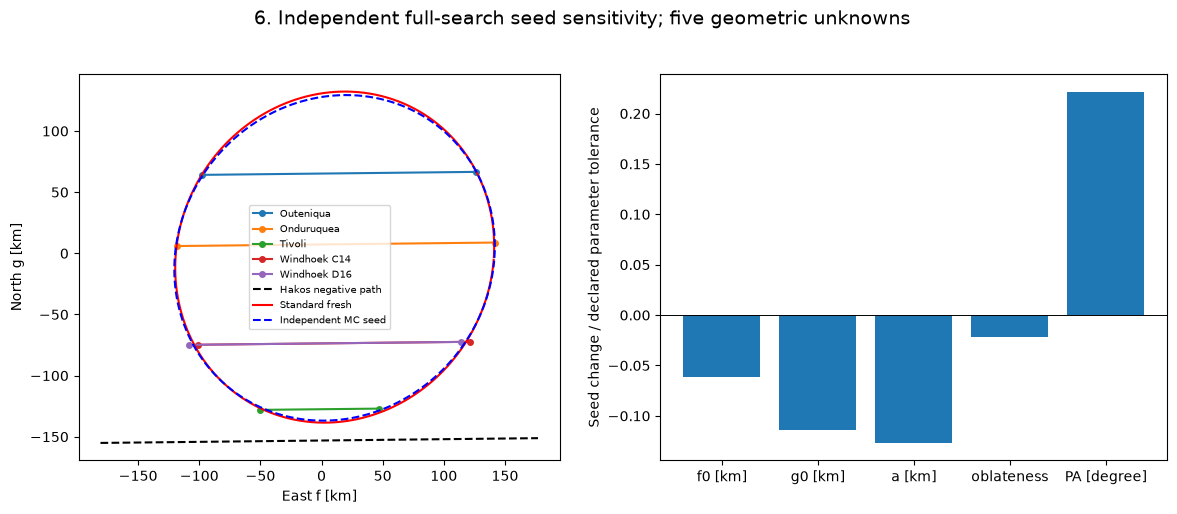

In [3]:
export=Path('D:/yan1/agent/AutoSkill/imaging-101-maintainer/research_batch5_20261021/astro_earth/figures/chariklo_occultation_silhouette')
figures=make_figures(data,output,stages,upstream,comparison,export)
for fig in figures:
    display(fig)
    plt.close(fig)


### Independent evaluation

The evaluator imports no solver functions. It builds the ellipse quadratic form independently and solves each measured local ray's quadratic intersection equation. All ten normalized contact-time shifts, zero missed positive rays, and zero negative-path penetration are mandatory. It also scores all five physical parameters, wraps pole-angle differences modulo180degrees, scores the full contour, and verifies that contour and parameters describe the same geometry.

Parameter and contour bounds come from the independently reproduced source delta-chi-square<1ensemble. Contact-time consistency is bounded from the original physical forward check. These criteria characterize the validated method and observations, rather than true topography. Shared-site correlations and example uncertainty weights limit statistical interpretation.


In [4]:
import subprocess
result=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],capture_output=True,text=True)
report=json.loads((root/'output/judge_report.json').read_text(encoding='utf8'))
print(json.dumps(report,indent=2));assert result.returncode==0,result.stderr
(export/'metrics.json').write_text(json.dumps({'fresh':report,'fresh_seconds':seconds,'retained_positive_only':len(stages['chi2']),'retained_continuous':int(stages['negative_clear'].sum()),'retained_exposure':int(exposure_clear.sum()),'independent_seed_best':seed_output['parameters'].tolist()},indent=2),encoding='utf8')


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "center_f_error": 0.0,
    "center_g_error": 0.0,
    "radius_error": 0.0,
    "oblateness_error": 0.0,
    "position_angle_error": 0.0,
    "contour_ncc": 1.0000000000000002,
    "contour_nrmse": 0.0,
    "contour_consistency_km": 1.3512214442612559e-14,
    "timing_sigma_rms": 0.4321838263325857,
    "missing_contact_count": 0,
    "negative_penetration_km": 0.0
  },
  "thresholds": {
    "center_f_error": {
      "comparison": "<=",
      "boundary": 1.6494378015777118
    },
    "center_g_error": {
      "comparison": "<=",
      "boundary": 5.4091788453559335
    },
    "radius_error": {
      "comparison": "<=",
      "boundary": 7.319274820044414
    },
    "oblateness_error": {
      "comparison": "<=",
      "boundary": 0.044554469252895634
    },
    "position_angle_error": {
      "comparison": "<=",
      "boundary": 39.73124188176298
    },
    "contour_ncc": {
      "comparison": ">=",
      "boundary": 0.99904462

1941

The actual reconstruction passes all parameter, contour and independent observation checks. Continuous and exposure-only negative constraints remove different portions of the original candidate ensemble, while preserving the same best ellipse. The seed comparison and correlated parameter scatter show why sparse occultation geometry does not determine an arbitrary surface or a unique three-dimensional body.


## 6. Conclusion

The 360 contour samples encode five ellipse parameters rather than 360 independent shape measurements. Contact-time residuals and negative-ray exclusion constrain a projected limb; teaching uncertainty weights and two instruments at one site limit formal confidence interpretations.
